<center> <img src = https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/hh%20label.jpg alt="drawing" style="width:400px;">

# <center> Проект: Анализ резюме из HeadHunter
   

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Исследование структуры данных

1. Прочитайте данные с помощью библиотеки Pandas. Совет: перед чтением обратите внимание на разделитель внутри файла. 

In [69]:
df = pd.read_csv('data/dst-3.0_16_1_hh_database.csv', sep=';', decimal=',')

# Вывод размерности в формате (число строк, число столбцов)
print(df.shape)

(44744, 12)


2. Выведите несколько первых (последних) строк таблицы, чтобы убедиться в том, что ваши данные не повреждены. Ознакомьтесь с признаками и их структурой.

In [70]:
df = pd.read_csv('data/dst-3.0_16_1_hh_database.csv', sep=';', decimal=',')

# Вывод первых 5 строк таблицы
print(df.head())

# Вывод последних 5 строк таблицы
print(df.tail())

# Вывод первых 10 значений конкретного столбца «Пол, возраст»
print(df['Пол, возраст'].head(10))

                                   Пол, возраст           ЗП  \
0    Мужчина ,  39 лет , родился 27 ноября 1979   29000 руб.   
1     Мужчина ,  60 лет , родился 20 марта 1959   40000 руб.   
2  Женщина ,  36 лет , родилась 12 августа 1982   20000 руб.   
3      Мужчина ,  38 лет , родился 25 июня 1980  100000 руб.   
4     Женщина ,  26 лет , родилась 3 марта 1993  140000 руб.   

                           Ищет работу на должность:  \
0                            Системный администратор   
1                               Технический писатель   
2                                           Оператор   
3  Веб-разработчик (HTML / CSS / JS / PHP / базы ...   
4                  Региональный менеджер по продажам   

                        Город, переезд, командировки  \
0  Советск (Калининградская область) , не готов к...   
1  Королев , не готов к переезду , готов к редким...   
2  Тверь , не готова к переезду , не готова к ком...   
3  Саратов , не готов к переезду , готов к редким...  

3. Выведите основную информацию о числе непустых значений в столбцах и их типах в таблице.

4. Обратите внимание на информацию о числе непустых значений.

In [71]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   Пол, возраст                     44744 non-null  str  
 1   ЗП                               44744 non-null  str  
 2   Ищет работу на должность:        44744 non-null  str  
 3   Город, переезд, командировки     44744 non-null  str  
 4   Занятость                        44744 non-null  str  
 5   График                           44744 non-null  str  
 6   Опыт работы                      44576 non-null  str  
 7   Последнее/нынешнее место работы  44743 non-null  str  
 8   Последняя/нынешняя должность     44742 non-null  str  
 9   Образование и ВУЗ                44744 non-null  str  
 10  Обновление резюме                44744 non-null  str  
 11  Авто                             44744 non-null  str  
dtypes: str(12)
memory usage: 437.5 MB


5. Выведите основную статистическую информацию о столбцах.


In [72]:
##статистика для каждого столбца (count - количество непустых значений; unique - количество уникальных значений;top - самое часто встречающееся значение (мода);freq - сколько раз встречается самое частое значение (top))
df.describe()

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
count,44744,44744,44744,44744,44744,44744,44576,44743,44742,44744,44744,44744
unique,16003,690,14929,10063,38,47,44413,30214,16927,40148,18838,2
top,"Мужчина , 32 года , родился 17 сентября 1986",50000 руб.,Системный администратор,"Москва , не готов к переезду , не готов к кома...",полная занятость,полный день,Опыт работы 10 лет 8 месяцев Апрель 2018 — по...,Индивидуальное предпринимательство / частная п...,Системный администратор,Высшее образование 2014 Московский технически...,07.05.2019 09:50,Не указано
freq,18,4064,3099,1261,30026,22727,3,935,2062,4,25,32268


# Преобразование данных

1. Начнем с простого - с признака **"Образование и ВУЗ"**. Его текущий формат это: **<Уровень образования год выпуска ВУЗ специальность...>**. Например:
* Высшее образование 2016 Московский авиационный институт (национальный исследовательский университет)...
* Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота…
Нас будет интересовать только уровень образования.

Создайте с помощью функции-преобразования новый признак **"Образование"**, который должен иметь 4 категории: "высшее", "неоконченное высшее", "среднее специальное" и "среднее".

Выполните преобразование, ответьте на контрольные вопросы и удалите признак "Образование и ВУЗ".

Совет: обратите внимание на структуру текста в столбце **"Образование и ВУЗ"**. Гарантируется, что текущий уровень образования соискателя всегда находится в первых 2ух слов и начинается с заглавной буквы. Воспользуйтесь этим.

*Совет: проверяйте полученные категории, например, с помощью метода unique()*


In [73]:
def get_education(arg):
# Соединяем первые 3 слова в одну строку и приводим к нижнему регистру для надежности
    edu = ' '.join(arg.split(' ')[:3]).lower()
    
    if 'высшее образование' in edu and 'неоконченное' not in edu:
        return 'высшее'
    elif 'неоконченное высшее' in edu:
        return 'неоконченное высшее'
    elif 'среднее специальное' in edu:
        return 'среднее специальное'
    elif 'среднее образование' in edu:
        return 'среднее'

# Создаем новый признак «Образование»
df['Образование'] = df['Образование и ВУЗ'].apply(get_education)

# Проверяем, что получилось ровно 4 категории и нет пропусков (NaN)
print(df['Образование'].value_counts(dropna=False))

# Удаляем исходный столбец «Образование и ВУЗ»
df = df.drop('Образование и ВУЗ', axis=1)

print(df['Образование'].unique())

Образование
высшее                 33863
среднее специальное     5765
неоконченное высшее     4557
среднее                  559
Name: count, dtype: int64
<ArrowStringArray>
['неоконченное высшее', 'высшее', 'среднее специальное', 'среднее']
Length: 4, dtype: str


2. Теперь нас интересует столбец **"Пол, возраст"**. Сейчас он представлен в формате **<Пол , возраст , дата рождения >**. Например:
* Мужчина , 39 лет , родился 27 ноября 1979 
* Женщина , 21 год , родилась 13 января 2000
Как вы понимаете, нам необходимо выделить каждый параметр в отдельный столбец.

Создайте два новых признака **"Пол"** и **"Возраст"**. При этом важно учесть:
* Признак пола должен иметь 2 уникальных строковых значения: 'М' - мужчина, 'Ж' - женщина. 
* Признак возраста должен быть представлен целыми числами.

Выполните преобразование, ответьте на контрольные вопросы и удалите признак **"Пол, возраст"** из таблицы.

*Совет: обратите внимание на структуру текста в столбце, в части на то, как разделены параметры пола, возраста и даты рождения между собой - символом ' , '. 
Гарантируется, что структура одинакова для всех строк в таблице. Вы можете воспользоваться этим.*


In [74]:
# Функция для выделения пола ('М' или 'Ж')
def get_gender(arg):
    gender = arg.split(' , ')[0].strip()
    if gender == 'Мужчина':
        return 'М'
    else:
        return 'Ж'

# Функция для выделения возраста (целое число)
def get_age(arg):
    age_str = arg.split(' , ')[1].strip()
    # Берем первое слово (число лет) и переводим в int
    return int(age_str.split(' ')[0])

# Создаем новые столбцы
df['Пол'] = df['Пол, возраст'].apply(get_gender)
df['Возраст'] = df['Пол, возраст'].apply(get_age)

# Проверяем уникальные значения пола и тип данных возраста
print("Уникальные значения пола:", df['Пол'].unique())
print("Тип данных возраста:", df['Возраст'].dtype)

# Удаляем исходный столбец «Пол, возраст»
df = df.drop('Пол, возраст', axis=1)

# Считаем долю женских резюме в процентах (округление до сотых)
female_percent = round(df['Пол'].value_counts(normalize=True)['Ж'] * 100, 2)
print("Процент женских резюме:", female_percent)

# Находим средний возраст соискателей (округление до десятых)
mean_age = round(df['Возраст'].mean(), 1)
print("Средний возраст соискателей:", mean_age)

Уникальные значения пола: <ArrowStringArray>
['М', 'Ж']
Length: 2, dtype: str
Тип данных возраста: int64
Процент женских резюме: 19.07
Средний возраст соискателей: 32.2


3. Следующим этапом преобразуем признак **"Опыт работы"**. Его текущий формат - это: **<Опыт работы: n лет m месяцев, периоды работы в различных компаниях…>**. 

Из столбца нам необходимо выделить общий опыт работы соискателя в месяцах, новый признак назовем "Опыт работы (месяц)"

Для начала обсудим условия решения задачи:
* Во-первых, в данном признаке есть пропуски. Условимся, что если мы встречаем пропуск, оставляем его как есть (функция-преобразование возвращает NaN)
* Во-вторых, в данном признаке есть скрытые пропуски. Для некоторых соискателей в столбце стоит значения "Не указано". Их тоже обозначим как NaN (функция-преобразование возвращает NaN)
* В-третьих, нас не интересует информация, которая описывается после указания опыта работы (периоды работы в различных компаниях)
* В-четвертых, у нас есть проблема: опыт работы может быть представлен только в годах или только месяцах. Например, можно встретить следующие варианты:
    * Опыт работы 3 года 2 месяца…
    * Опыт работы 4 года…
    * Опыт работы 11 месяцев…
    * Учитывайте эту особенность в вашем коде

Учитывайте эту особенность в вашем коде

В результате преобразования у вас должен получиться столбец, содержащий информацию о том, сколько месяцев проработал соискатель.
Выполните преобразование, ответьте на контрольные вопросы и удалите столбец **"Опыт работы"** из таблицы.


In [75]:
import numpy as np
import pandas as pd

def get_experience(arg):
    # Проверяем на обычный пропуск (NaN) или строку 'Не указано'
    if pd.isnull(arg) or arg == 'Не указано':
        return np.nan
    
    # Берем только начало строки (первые 7 слов)
    words = arg.split(' ')[:7]
    
    years = 0
    months = 0
    
    # Списки ключевых слов для проверки
    year_words = ['год', 'года', 'лет']
    month_words = ['месяц', 'месяца', 'месяцев']
    
    for i in range(len(words)):
        if words[i] in year_words:
            years = int(words[i - 1])
        if words[i] in month_words:
            months = int(words[i - 1])
            
    return years * 12 + months

# Создаем новый признак «Опыт работы (месяц)»
df['Опыт работы (месяц)'] = df['Опыт работы'].apply(get_experience)

# Удаляем исходный столбец «Опыт работы»
df = df.drop('Опыт работы', axis=1)

# Считаем медианный опыт работы (в месяцах)
print("Медианный опыт работы (мес.):", df['Опыт работы (месяц)'].median())

Медианный опыт работы (мес.): 100.0


4. Хорошо идем! Следующий на очереди признак "Город, переезд, командировки". Информация в нем представлена в следующем виде: **<Город , (метро) , готовность к переезду (города для переезда) , готовность к командировкам>**. В скобках указаны необязательные параметры строки. Например, можно встретить следующие варианты:

* Москва , не готов к переезду , готов к командировкам
* Москва , м. Беломорская , не готов к переезду, не готов к командировкам
* Воронеж , готов к переезду (Сочи, Москва, Санкт-Петербург) , готов к командировкам

Создадим отдельные признаки **"Город"**, **"Готовность к переезду"**, **"Готовность к командировкам"**. При этом важно учесть:

* Признак **"Город"** должен содержать только 4 категории: "Москва", "Санкт-Петербург" и "город-миллионник" (их список ниже), остальные обозначьте как "другие".

    Список городов-миллионников:
    
   <code>million_cities = ['Новосибирск', 'Екатеринбург','Нижний Новгород','Казань', 'Челябинск','Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж','Волгоград']
    </code>
    Инфорация о метро, рядом с которым проживает соискатель нас не интересует.
* Признак **"Готовность к переезду"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к переезду в признаке "Город, переезд, командировки". Например:
    * … , готов к переезду , …
    * … , не готова к переезду , …
    * … , готова к переезду (Москва, Санкт-Петербург, Ростов-на-Дону)
    * … , хочу переехать (США) , …
    
    Нас интересует только сам факт возможности или желания переезда.
* Признак **"Готовность к командировкам"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к командировкам в признаке "Город, переезд, командировки". Например:
    * … , готов к командировкам , … 
    * … , готова к редким командировкам , …
    * … , не готов к командировкам , …
    
    Нас интересует только сам факт готовности к командировке.
    
    Еще один важный факт: при выгрузки данных у некоторых соискателей "потерялась" информация о готовности к командировкам. Давайте по умолчанию будем считать, что такие соискатели не готовы к командировкам.
    
Выполните преобразования и удалите столбец **"Город, переезд, командировки"** из таблицы.

*Совет: обратите внимание на то, что структура текста может меняться в зависимости от указания ближайшего метро. Учите это, если будете использовать порядок слов в своей программе.*


In [76]:
# 1. Функция для определения города
def get_city(arg):
    million_cities = [
        'Новосибирск', 'Екатеринбург', 'Нижний Новгород', 'Казань', 
        'Челябинск', 'Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 
        'Красноярск', 'Пермь', 'Воронеж', 'Волгоград'
    ]
    city = arg.split(' , ')[0].strip()
    
    if city in ['Москва', 'Санкт-Петербург']:
        return city
    elif city in million_cities:
        return 'город-миллионник'
    else:
        return 'другие'

# 2. Функция для определения готовности к переезду
def get_ready_to_move(arg):
    # Убираем название города и метро
    parts = arg.split(' , ')
    if 'м.' in parts[1]:
        move_info = parts[2]
    else:
        move_info = parts[1]
        
    if 'не готов' in move_info or 'не готова' in move_info:
        return False
    else:
        return True

# 3. Функция для определения готовности к командировкам
def get_ready_for_business_trips(arg):
    parts = arg.split(' , ')
    # Проверяем последний элемент, если в нем вообще упоминаются командировки
    last_part = parts[-1]
    if 'командировк' in last_part:
        if 'не готов' in last_part or 'не готова' in last_part:
            return False
        else:
            return True
    else:
        # Если информация о командировках потерялась, по условию возвращаем False
        return False

# Применяем функции и создаем три новых столбца
df['Город'] = df['Город, переезд, командировки'].apply(get_city)
df['Готовность к переезду'] = df['Город, переезд, командировки'].apply(get_ready_to_move)
df['Готовность к командировкам'] = df['Город, переезд, командировки'].apply(get_ready_for_business_trips)

# Удаляем исходный столбец
df = df.drop('Город, переезд, командировки', axis=1)

# Считаем процент соискателей из Санкт-Петербурга (округление до целого)
spb_percent = round(df['Город'].value_counts(normalize=True)['Санкт-Петербург'] * 100)
print("Процент соискателей из Санкт-Петербурга:", spb_percent)
# Фильтруем соискателей с True в обоих столбцах и делим их число на общее количество строк

both_ready_percent = round(
    df[df['Готовность к переезду'] & df['Готовность к командировкам']].shape[0] / df.shape[0] * 100
)
print("Процент готовых к переездам и командировкам:", both_ready_percent)

Процент соискателей из Санкт-Петербурга: 11
Процент готовых к переездам и командировкам: 32


5. Рассмотрим поближе признаки **"Занятость"** и **"График"**. Сейчас признаки представляют собой набор категорий желаемой занятости (полная занятость, частичная занятость, проектная работа, волонтерство, стажировка) и желаемого графика работы (полный день, сменный график, гибкий график, удаленная работа, вахтовый метод).
На сайте hh.ru соискатель может указывать различные комбинации данных категорий, например:
* полная занятость, частичная занятость
* частичная занятость, проектная работа, волонтерство
* полный день, удаленная работа
* вахтовый метод, гибкий график, удаленная работа, полная занятость

Такой вариант признаков имеет множество различных комбинаций, а значит множество уникальных значений, что мешает анализу. Нужно это исправить!

Давайте создадим признаки-мигалки для каждой категории: если категория присутствует в списке желаемых соискателем, то в столбце на месте строки рассматриваемого соискателя ставится True, иначе - False.

Такой метод преобразования категориальных признаков называется One Hot Encoding и его схема представлена на рисунке ниже:
<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/ohe.jpg>
Выполните данное преобразование для признаков "Занятость" и "График", ответьте на контрольные вопросы, после чего удалите их из таблицы

In [77]:
# Списки всех категорий из условия задачи
employments = [
    'полная занятость', 
    'частичная занятость', 
    'проектная работа', 
    'волонтерство', 
    'стажировка'
]

charts = [
    'полный день', 
    'сменный график', 
    'гибкий график', 
    'удаленная работа', 
    'вахтовый метод'
]

# Создаем столбцы-«мигалки» для занятости
for employment in employments:
    df[employment] = df['Занятость'].apply(lambda x: employment in x)

# Создаем столбцы-«мигалки» для графика работы
for chart in charts:
    df[chart] = df['График'].apply(lambda x: chart in x)

# Удаляем исходные столбцы «Занятость» и «График»
df = df.drop(['Занятость', 'График'], axis=1)

# 1. Сколько людей ищут проектную работу и волонтерство
proj_vol = df[df['проектная работа'] & df['волонтерство']].shape
print("Проектная работа и волонтерство:", proj_vol)

# 2. Сколько людей хотят работать вахтовым методом и с гибким графиком
vahta_flex = df[df['вахтовый метод'] & df['гибкий график']].shape
print("Вахтовый метод и гибкий график:", vahta_flex)

Проектная работа и волонтерство: (436, 23)
Вахтовый метод и гибкий график: (2311, 23)


6. (2 балла) Наконец, мы добрались до самого главного и самого важного - признака заработной платы **"ЗП"**. 
В чем наша беда? В том, что помимо желаемой заработной платы соискатель указывает валюту, в которой он бы хотел ее получать, например:
* 30000 руб.
* 50000 грн.
* 550 USD

Нам бы хотелось видеть заработную плату в единой валюте, например, в рублях. Возникает вопрос, а где взять курс валют по отношению к рублю?

На самом деле язык Python имеет в арсенале огромное количество возможностей получения данной информации, от обращения к API Центробанка, до использования специальных библиотек, например pycbrf. Однако, это не тема нашего проекта.

Поэтому мы пойдем в лоб: обратимся к специальным интернет-ресурсам для получения данных о курсе в виде текстовых файлов. Например, MDF.RU, данный ресурс позволяет удобно экспортировать данные о курсах различных валют и акций за указанные периоды в виде csv файлов. Мы уже сделали выгрузку курсов валют, которые встречаются в наших данных за период с 29.12.2017 по 05.12.2019. Скачать ее вы можете **на платформе**

Создайте новый DataFrame из полученного файла. В полученной таблице нас будут интересовать столбцы:
* "currency" - наименование валюты в ISO кодировке,
* "date" - дата, 
* "proportion" - пропорция, 
* "close" - цена закрытия (последний зафиксированный курс валюты на указанный день).


Перед вами таблица соответствия наименований иностранных валют в наших данных и их общепринятых сокращений, которые представлены в нашем файле с курсами валют. Пропорция - это число, за сколько единиц валюты указан курс в таблице с курсами. Например, для казахстанского тенге курс на 20.08.2019 составляет 17.197 руб. за 100 тенге, тогда итоговый курс равен - 17.197 / 100 = 0.17197 руб за 1 тенге.
Воспользуйтесь этой информацией в ваших преобразованиях.

<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/table.jpg>


Осталось только понять, откуда брать дату, по которой определяется курс? А вот же она - в признаке **"Обновление резюме"**, в нем содержится дата и время, когда соискатель выложил текущий вариант своего резюме. Нас интересует только дата, по ней бы и будем сопоставлять курсы валют.

Теперь у нас есть вся необходимая информация для того, чтобы создать признак "ЗП (руб)" - заработная плата в рублях.

После ответа на контрольные вопросы удалите исходный столбец заработной платы "ЗП" и все промежуточные столбцы, если вы их создавали.

Итак, давайте обсудим возможный алгоритм преобразования: 
1. Перевести признак "Обновление резюме" из таблицы с резюме в формат datetime и достать из него дату. В тот же формат привести признак "date" из таблицы с валютами.
2. Выделить из столбца "ЗП" сумму желаемой заработной платы и наименование валюты, в которой она исчисляется. Наименование валюты перевести в стандарт ISO согласно с таблицей выше.
3. Присоединить к таблице с резюме таблицу с курсами по столбцам с датой и названием валюты (подумайте, какой тип объединения надо выбрать, чтобы в таблице с резюме сохранились данные о заработной плате, изначально представленной в рублях). Значение close для рубля заполнить единицей 1 (курс рубля самого к себе)
4. Умножить сумму желаемой заработной платы на присоединенный курс валюты (close) и разделить на пропорцию (обратите внимание на пропуски после объединения в этих столбцах), результат занести в новый столбец "ЗП (руб)".


In [78]:
# 1. Загружаем таблицу с курсами валют
rates = pd.read_csv('data/ExchangeRates.csv')

# 2. Приводим даты в обеих таблицах к единому формату (без времени)
df['Обновление резюме'] = pd.to_datetime(df['Обновление резюме'], dayfirst=True).dt.date
rates['date'] = pd.to_datetime(rates['date'], format='%d/%m/%y').dt.date

# 3. Извлекаем сумму ЗП ([0]) и название валюты ([1])
def get_salary_num(arg):
    return float(arg.split(' ')[0])

def get_salary_currency(arg):
    currency_dict = {
        'грн': 'UAH',
        'USD': 'USD',
        'EUR': 'EUR',
        'белруб': 'BYN',
        'KGS': 'KGS',
        'сум': 'UZS',
        'AZN': 'AZN',
        'KZT': 'KZT'
    }
    curr = arg.split(' ')[1].replace('.', '')
    if curr == 'руб':
        return 'RUB'
    else:
        return currency_dict[curr]

df['ЗП (tmp)'] = df['ЗП'].apply(get_salary_num)
df['Курс (tmp)'] = df['ЗП'].apply(get_salary_currency)

# 4. Присоединяем таблицу с курсами по дате и валюте
df = df.merge(
    rates[['currency', 'date', 'close', 'proportion']],
    left_on=['Курс (tmp)', 'Обновление резюме'],
    right_on=['currency', 'date'],
    how='left'
)

# 5. Заполняем пропуски (для RUB) единицами и считаем итоговую ЗП в рублях
df['close'] = df['close'].fillna(1)
df['proportion'] = df['proportion'].fillna(1)
df['ЗП (руб)'] = df['ЗП (tmp)'] * df['close'] / df['proportion']

# 6. Удаляем исходный столбец 'ЗП' и все временные столбцы
df = df.drop(['ЗП', 'ЗП (tmp)', 'Курс (tmp)', 'currency', 'date', 'close', 'proportion'], axis=1)

# 7. Считаем медианную зарплату в тысячах рублей с округлением до целого
median_salary = round(df['ЗП (руб)'].median() / 1000)
print("Медианная ЗП (тыс. руб.):", median_salary)

Медианная ЗП (тыс. руб.): 59


In [86]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Ищет работу на должность:        44744 non-null  str    
 1   Последнее/нынешнее место работы  44743 non-null  str    
 2   Последняя/нынешняя должность     44742 non-null  str    
 3   Обновление резюме                44744 non-null  object 
 4   Авто                             44744 non-null  str    
 5   Образование                      44744 non-null  str    
 6   Пол                              44744 non-null  str    
 7   Возраст                          44744 non-null  int64  
 8   Опыт работы (месяц)              44574 non-null  float64
 9   Город                            44744 non-null  str    
 10  Готовность к переезду            44744 non-null  bool   
 11  Готовность к командировкам       44744 non-null  bool   
 12  полная занятость             

# Исследование зависимостей в данных

1. Постройте распределение признака **"Возраст"**. Опишите распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится возраст большинства соискателей? Есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

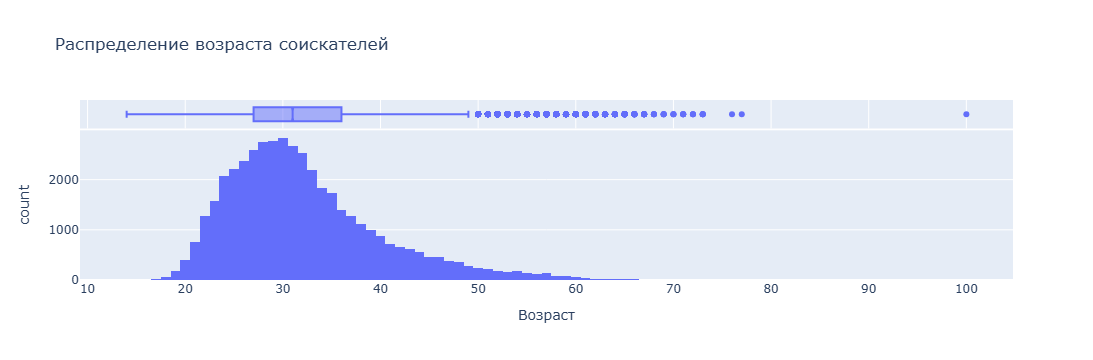

Мода возраста: 0    30
Name: Возраст, dtype: int64


In [87]:
import plotly.express as px

# Строим гистограмму возраста с коробчатой диаграммой (box plot) сверху
fig = px.histogram(
    data_frame=df,
    x='Возраст',
    title='Распределение возраста соискателей',
    marginal='box'
)
fig.show()

# Выводим значение моды в консоль для проверки
print("Мода возраста:", df['Возраст'].mode())

**Предельные значения и основной интервал:** минимальный возраст - 14 лет, максимальный - 100 лет (аномальное значение). 
Возраст большинства соискателей (межквартильный размах от 25% до 75% квантиля на коробчатой диаграмме) находится в интервале примерно от 27 до 36 лет (медиана - 31 год).

**Аномалии:** да, в данных есть выброс - возраст 100 лет (возраст старше 70–75 лет значительно превышает верхнюю границу коробчатой диаграммы и кажется маловероятным для активного поиска работы)

2. Постройте распределение признака **"Опыт работы (месяц)"**. Опишите данное распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится опыт работы большинства соискателей? Есть ли аномалии для признака опыта работы, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

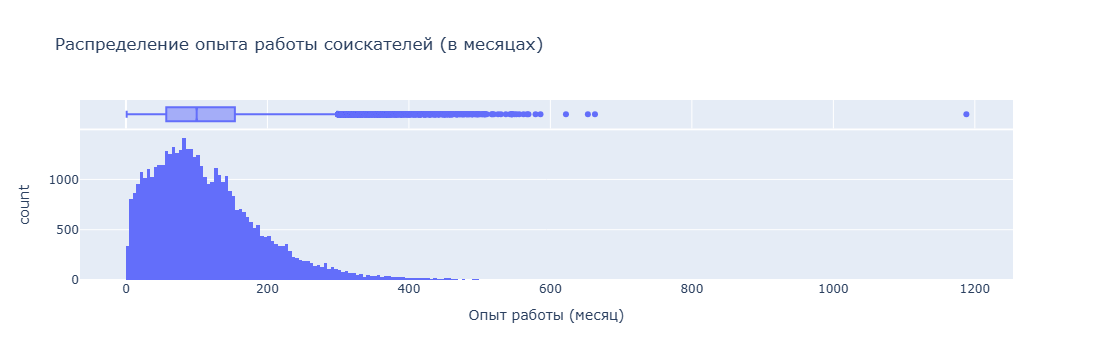

Мода опыта работы (мес.): 0    81.0
Name: Опыт работы (месяц), dtype: float64
Максимальный опыт работы (мес.): 1188.0


In [88]:
import plotly.express as px

# Строим гистограмму и коробчатую диаграмму опыта работы
fig = px.histogram(
    data_frame=df,
    x='Опыт работы (месяц)',
    title='Распределение опыта работы соискателей (в месяцах)',
    marginal='box'
)
fig.show()

# Выводим точные показатели 
print("Мода опыта работы (мес.):", df['Опыт работы (месяц)'].mode())
print("Максимальный опыт работы (мес.):", df['Опыт работы (месяц)'].max())

**Мода опыта работы:** 81 месяц (около 6,5-7 лет; при автоматической разбивке гистограммы пик приходится на интервал 80–84 месяца).
Предельные значения и основной интервал: минимальный опыт - 1 месяц (или 0, если в данных есть округления), максимальный - 1188 месяцев. Опыт большинства соискателей (межквартильный размах от Q1 до Q3 на коробчатой диаграмме) лежит в интервале от 57 до 154 месяцев (примерно от 4,5 до 13 лет), медиана - 100 месяцев.

**Аномалии:** да, в данных присутствует явный выброс - 1188 месяцев (99 лет стажа), а также значения выше 600–700 месяцев (50+ лет стажа), которые превышают возможный трудовой стаж человека.

3. Постройте распределение признака **"ЗП (руб)"**. Опишите данное распределение, отвечая на следующие вопросы: каковы предельные значения признака, в каком примерном интервале находится заработная плата большинства соискателей? Есть ли аномалии для признака возраста? Обратите внимание на гигантские размеры желаемой заработной платы.
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*


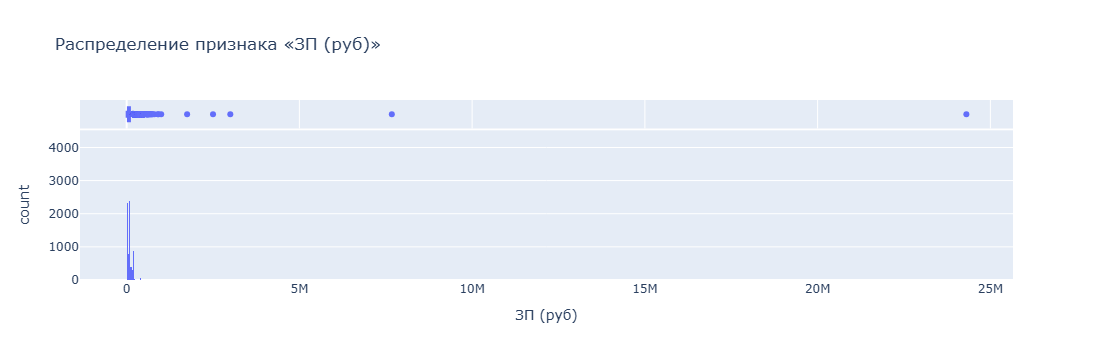

In [89]:
import plotly.express as px

fig = px.histogram(
    data_frame=df,
    x='ЗП (руб)',
    title='Распределение признака «ЗП (руб)»',
    marginal='box'
)
fig.show()

**Мода распределения:** наиболее частая желаемая заработная плата соискателей составляет 50 000 рублей (50 тыс. руб.).

**Предельные значения признака:** минимальная желаемая зарплата равна 1 рублю, максимальная - 24 304 876 рублям (~24,3 млн руб.).

**Основной интервал значений:** заработная плата большинства соискателей (межквартильный размах от 25-го до 75-го квантиля на коробчатой диаграмме) находится в интервале примерно от 37 000 до 95 000 рублей (медиана - около 59 000 рублей). Из-за наличия гигантских выбросов справа основная масса данных на гистограмме сильно сжата в левой части графика.

**Аномалии:** да, в распределении присутствуют явные выбросы с обеих сторон:
1. Неправдоподобно высокие значения (выше 1 млн руб.): в таблице есть 5 резюме с запросами от 1,75 млн до 24,3 млн рублей - вероятнее всего, это опечатки (лишние нули) или ошибка при выборе валюты (например, указание зарплаты в рублях вместо узбекских сумов или белорусских рублей).
2. Аномально низкие значения (ниже 1000 руб., вплоть до 1 руб.): такие суммы не соответствуют реальному рынку труда и появляются, когда соискатели ставят символическую цифру «1» или «100» вместо реальных ожиданий.



4. Постройте диаграмму, которая показывает зависимость **медианной** желаемой заработной платы (**"ЗП (руб)"**) от уровня образования (**"Образование"**). Используйте для диаграммы данные о резюме, где желаемая заработная плата меньше 1 млн рублей.
*Сделайте выводы по представленной диаграмме: для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы? Как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы?*

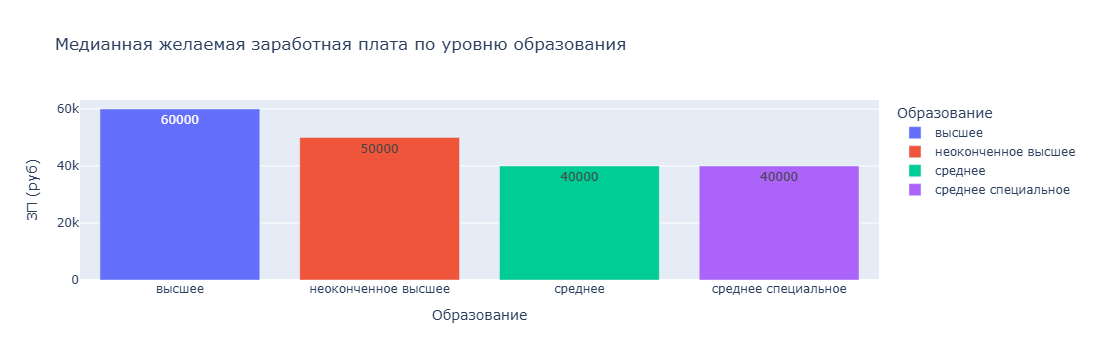

           Образование  ЗП (руб)
0               высшее   60000.0
1  неоконченное высшее   50000.0
2              среднее   40000.0
3  среднее специальное   40000.0


In [90]:
import plotly.express as px

# Фильтруем данные (ЗП < 1 млн руб.) и считаем медианную ЗП по каждому уровню образования
bar_data = df[df['ЗП (руб)'] < 1_000_000].groupby('Образование', as_index=False)['ЗП (руб)'].median()

# Строим столбчатую диаграмму
fig = px.bar(
    data_frame=bar_data,
    x='Образование',
    y='ЗП (руб)',
    color='Образование',
    text='ЗП (руб)',
    title='Медианная желаемая заработная плата по уровню образования'
)
fig.show()

# Выводим таблицу в консоль для проверки
print(bar_data.sort_values(by='ЗП (руб)', ascending=False))

**Наибольшая медианная зарплата** наблюдается у соискателей с **высшим** образованием (60 000 руб.).
Далее идут неоконченное высшее (50 000 руб.), затем среднее и среднее специальное - у обеих категорий медианный уровень зарплаты наименьший и одинаковый (40 000 руб.).
**Важность признака для прогнозирования:** да, признак уровня образования однозначно важен для прогнозирования заработной платы - на диаграмме прослеживается чёткая прямая зависимость: чем выше ступень образования соискателя, тем выше его зарплатные ожидания (разница между высшим и средним образованием составляет 20 000 рублей, или 50%).

5. Постройте диаграмму, которая показывает распределение желаемой заработной платы (**"ЗП (руб)"**) в зависимости от города (**"Город"**). Используйте для диаграммы данные о резюме, где желая заработная плата меньше 1 млн рублей.
*Сделайте выводы по полученной диаграмме: как соотносятся медианные уровни желаемой заработной платы и их размах в городах? Как вы считаете, важен ли признак города при прогнозировании заработной платы?*

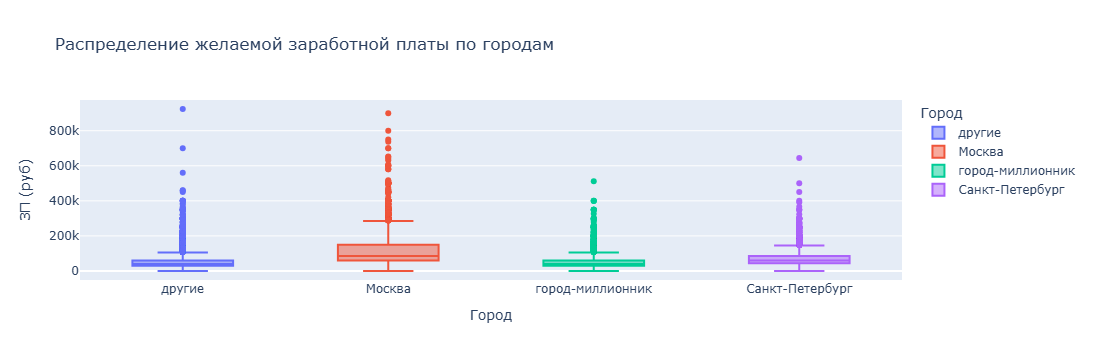

                   median       max
Город                              
Москва            85000.0  900000.0
Санкт-Петербург   60000.0  645171.0
город-миллионник  40000.0  511681.6
другие            40000.0  923983.0


In [91]:
import plotly.express as px

# Фильтруем резюме с ЗП < 1 млн руб.
box_data = df[df['ЗП (руб)'] < 1_000_000]

# Строим коробчатую диаграмму распределения ЗП по городам
fig = px.box(
    data_frame=box_data,
    x='Город',
    y='ЗП (руб)',
    color='Город',
    title='Распределение желаемой заработной платы по городам'
)
fig.show()

# Выводим медианные и максимальные значения по каждой категории городов
print(box_data.groupby('Город')['ЗП (руб)'].agg(['median', 'max']))


Лидером по уровню ожиданий является **Москва**: медианная зарплата составляет 85 000 рублей, а межквартильный размах (от 60 000 до 150 000 руб.) значительно шире, чем в других регионах.

На втором месте идёт **Санкт-Петербург**: медианная зарплата равна 60 000 рублей (размах основной массы - от 45 000 до 85 000 руб.).
В городах-миллионниках и других городах медианные зарплаты и размах ожиданий совпадают: медиана равна 40 000 рублей, а основная часть запросов лежит в интервале от 30 000 до 60 000 рублей.

**Важность признака города для прогнозирования:** да, признак города крайне важен при прогнозировании заработной платы, так как зарплатные ожидания в Москве более чем в два раза превышают ожидания в регионах, а Санкт-Петербург занимает промежуточное положение.

6. Постройте **многоуровневую столбчатую диаграмму**, которая показывает зависимость медианной заработной платы (**"ЗП (руб)"**) от признаков **"Готовность к переезду"** и **"Готовность к командировкам"**. Проанализируйте график, сравнив уровень заработной платы в категориях.

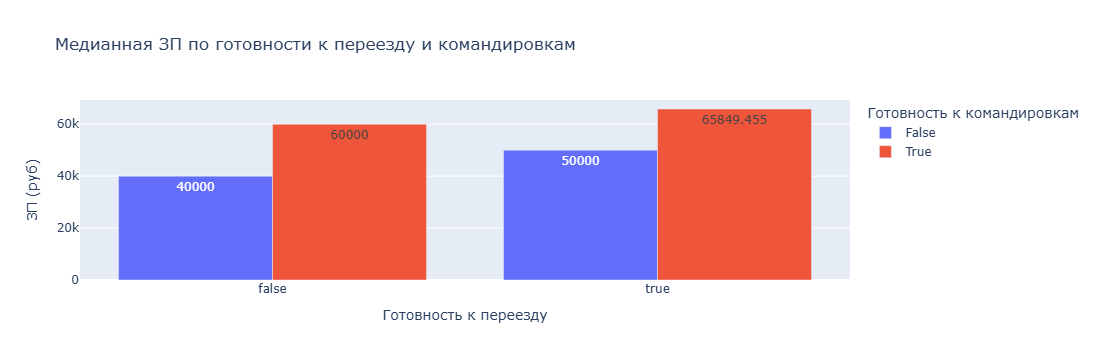

   Готовность к переезду  Готовность к командировкам   ЗП (руб)
0                  False                       False  40000.000
1                  False                        True  60000.000
2                   True                       False  50000.000
3                   True                        True  65849.455
Ответ (тыс. руб.): 66


In [93]:
import plotly.express as px

# Группируем данные по готовности к переезду и командировкам, считаем медианную ЗП
bar_data = df.groupby(
    ['Готовность к переезду', 'Готовность к командировкам'],
    as_index=False
)['ЗП (руб)'].median()

# Строим многоуровневую столбчатую диаграмму
fig = px.bar(
    data_frame=bar_data,
    x='Готовность к переезду',
    y='ЗП (руб)',
    color='Готовность к командировкам',
    barmode='group',
    text='ЗП (руб)',
    title='Медианная ЗП по готовности к переезду и командировкам'
)
fig.show()

# Выводим таблицу в консоль и считаем ответ в тысячах рублей
print(bar_data)
both_true_salary = bar_data[
    (bar_data['Готовность к переезду'] == True) & 
    (bar_data['Готовность к командировкам'] == True)
]['ЗП (руб)'].values
print("Ответ (тыс. руб.):", round(df[df['Готовность к переезду'] & df['Готовность к командировкам']]['ЗП (руб)'].median() / 1000))



Люди, которые **готовы ездить в командировки**, в среднем хотят получать больше денег (от 60 до 66 тысяч рублей), чем те, кто **не готов** (от 40 до 50 тысяч рублей).

Если человек готов переехать, это тоже увеличивает его ожидания по зарплате на 6-10 тысяч рублей в любой группе.

Самая маленькая средняя зарплата (40 тысяч рублей) у тех, кто не хочет ни переезжать, ни ездить в командировки. А самая большая (около 66 тысяч рублей) - у тех, кто согласен и на то, и на другое.

7. Постройте сводную таблицу, иллюстрирующую зависимость **медианной** желаемой заработной платы от возраста (**"Возраст"**) и образования (**"Образование"**). На полученной сводной таблице постройте **тепловую карту**. Проанализируйте тепловую карту, сравнив показатели внутри групп.

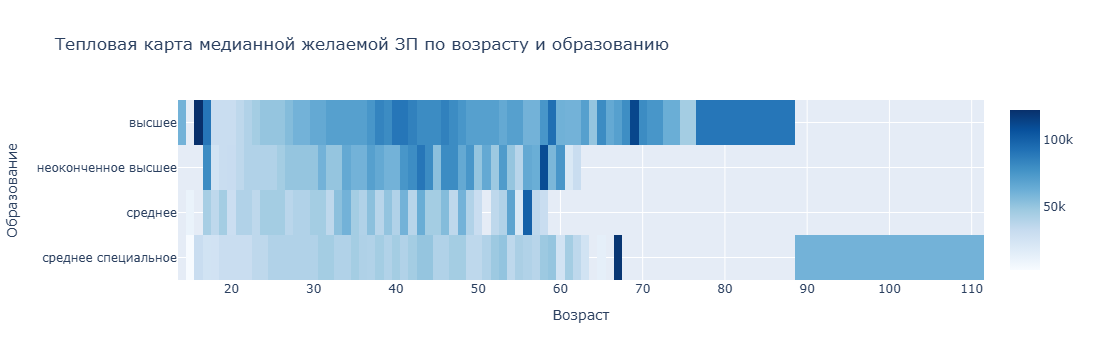

In [94]:
import plotly.express as px

# 1. Строим сводную таблицу (индексы - Образование, столбцы - Возраст, значения - медианная ЗП)
pivot = df.pivot_table(
    values='ЗП (руб)',
    index='Образование',
    columns='Возраст',
    aggfunc='median'
)

# 2. Строим тепловую карту по сводной таблице
fig = px.imshow(
    pivot,
    aspect='auto',
    color_continuous_scale='Blues',
    title='Тепловая карта медианной желаемой ЗП по возрасту и образованию'
)
fig.show()

**Высшее образование.** Здесь карьерный рост и рост зарплаты идут активнее всего: зарплата заметно прибавляет примерно с 22 лет, достигает пика в 40–45 лет (около 90–100 тыс. руб.), а потом плавно снижается.

**Неоконченное высшее.** Здесь рост зарплатных ожиданий идет медленнее, чем у выпускников вузов. Пик приходится примерно на 35–43 года (около 60–75 тыс. руб.).

**Среднее специальное и среднее образование.** В этих группах зарплатные ожидания на протяжении всей карьеры остаются примерно на одном уровне (40–50 тыс. руб.) и почти не растут с возрастом.

**Аномалии.** На краях возрастной шкалы (у совсем молодых или у очень пожилых соискателей) встречаются «выбросы» - высокие зарплатные ожидания в 16–18 лет или, например, 65 лет. Обычно это связано с единичными случаями: ошибками при заполнении анкеты или особыми резюме (например, человек очень опытный, но резюме оформлено слабо).

8. Постройте **диаграмму рассеяния**, показывающую зависимость опыта работы (**"Опыт работы (месяц)"**) от возраста (**"Возраст"**). Опыт работы переведите из месяцев в года, чтобы признаки были в едином масштабе. Постройте на графике дополнительно прямую, проходящую через точки (0, 0) и (100, 100). Данная прямая соответствует значениям, когда опыт работы равен возрасту человека. Точки, лежащие на этой прямой и выше нее - аномалии в наших данных (опыт работы больше либо равен возрасту соискателя)

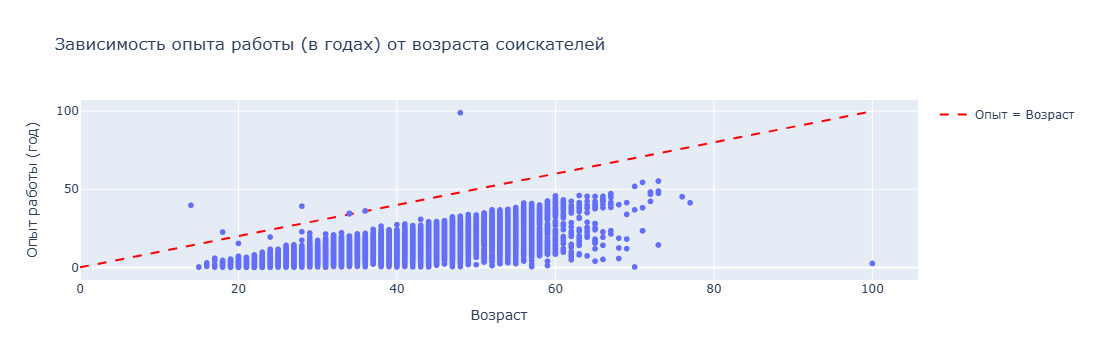

Точек строго выше прямой: 7


In [95]:
import plotly.express as px

# Создаем копию или временную таблицу, переводим опыт работы из месяцев в годы
scatter_data = df.copy()
scatter_data['Опыт работы (год)'] = scatter_data['Опыт работы (месяц)'] / 12

# Строим диаграмму рассеяния
fig = px.scatter(
    data_frame=scatter_data,
    x='Возраст',
    y='Опыт работы (год)',
    title='Зависимость опыта работы (в годах) от возраста соискателей'
)

# Добавляем прямую, проходящую через точки (0, 0) и (100, 100)
fig.add_scatter(
    x=[0, 100],
    y=[0, 100],
    mode='lines',
    name='Опыт = Возраст',
    line=dict(color='red', dash='dash')
)
fig.show()

# Считаем количество точек, лежащих строго выше прямой (опыт в годах > возраста)
outliers_above = scatter_data[scatter_data['Опыт работы (год)'] > scatter_data['Возраст']]
print("Точек строго выше прямой:", outliers_above.shape[0])

**Связь возраста и опыта.** Чем старше соискатель, тем больше у него стаж - зависимость прямая. При этом в среднем стаж меньше возраста примерно на 18–22 года: это нормально, ведь люди обычно начинают работать после учебы.

**Разброс данных.** У более взрослых кандидатов (старше 40 лет) стаж сильно различается: у одних непрерывный опыт 20–25 лет, у других - меньше (например, из‑за смены профессии или перерыва).

**Аномалии.** 
1. Опыт больше возраста (7 резюме): явные ошибки - например, человеку 16–20 лет, а стаж указан 20–30 лет; или возраст 100 лет при стаже 99 лет.
2. Слишком ранний старт: есть анкеты, где стаж почти равен возрасту - разница всего 14–16 лет. Получается, будто человек начал работать в раннем детстве, что маловероятно.

**Дополнительные баллы**

Для получения 2 дополнительных баллов по разведывательному анализу постройте еще два любых содержательных графика или диаграммы, которые помогут проиллюстрировать влияние признаков/взаимосвязь между признаками/распределения признаков. Приведите выводы по ним. Желательно, чтобы в анализе участвовали признаки, которые мы создавали ранее в разделе "Преобразование данных".


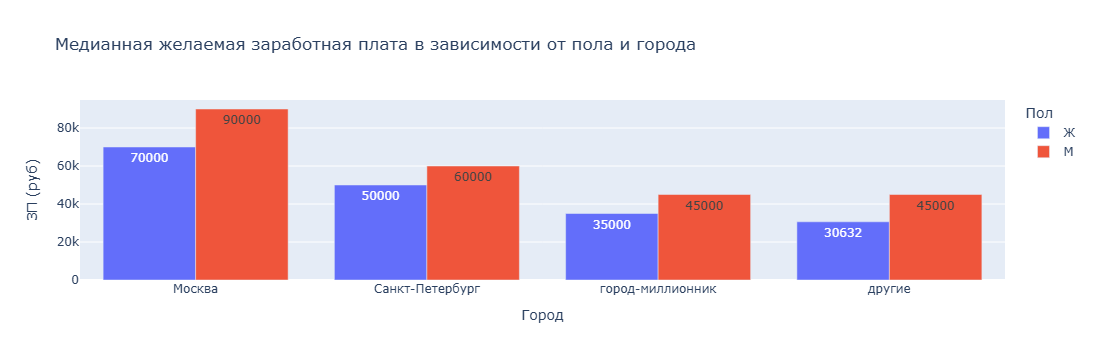

In [96]:
import plotly.express as px

# Группируем данные по полу и городу, вычисляя медианную ЗП (для ЗП < 1 млн руб.)
gender_city_data = df[df['ЗП (руб)'] < 1_000_000].groupby(
    ['Город', 'Пол'],
    as_index=False
)['ЗП (руб)'].median()

fig1 = px.bar(
    data_frame=gender_city_data,
    x='Город',
    y='ЗП (руб)',
    color='Пол',
    barmode='group',
    text='ЗП (руб)',
    title='Медианная желаемая заработная плата в зависимости от пола и города'
)
fig1.show()

Во всех городах **мужчины** в среднем указывают в резюме более высокую зарплату, чем **женщины.**

**Где разрыв больше.** Самая большая разница - в Москве: мужчины хотят 90 000 рублей, женщины - 70 000 (разница 20 000). В Санкт‑Петербурге - 65 000 против 50 000. В других крупных городах и регионах разница поменьше - примерно 10 000 рублей (45 000 против 35 000).

**Что важно для прогноза.** И пол, и город заметно влияют на зарплатные ожидания, причем эти факторы усиливают друг друга - их обязательно нужно учитывать в модели.

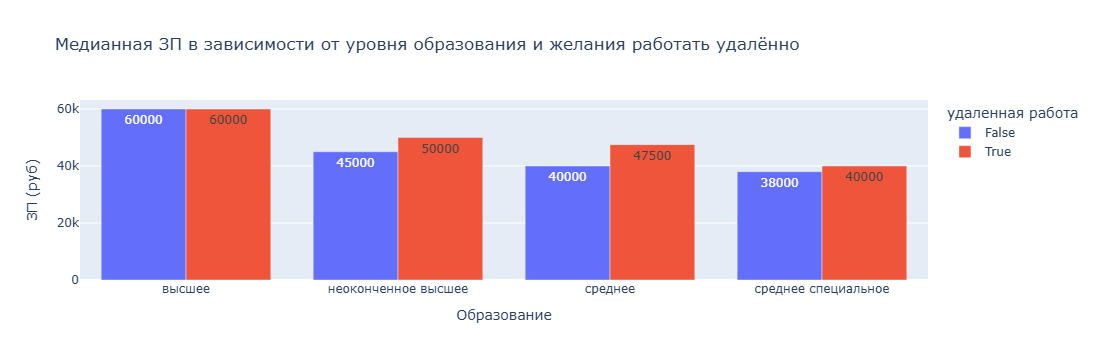

In [97]:
# Группируем данные по уровню образования и готовности к удаленной работе
remote_edu_data = df[df['ЗП (руб)'] < 1_000_000].groupby(
    ['Образование', 'удаленная работа'],
    as_index=False
)['ЗП (руб)'].median()

fig2 = px.bar(
    data_frame=remote_edu_data,
    x='Образование',
    y='ЗП (руб)',
    color='удаленная работа',
    barmode='group',
    text='ЗП (руб)',
    title='Медианная ЗП в зависимости от уровня образования и желания работать удаленно'
)
fig2.show()

**Связь удаленной работы с уровнем ожиданий:** соискатели, рассматривающие удаленную работу (True), в среднем претендуют на более высокую или сопоставимую заработную плату по сравнению с теми, кто ищет исключительно офисный/очный формат (False).

**Различия внутри групп образования:** наиболее заметная прибавка к медианной зарплате при готовности к удаленному формату наблюдается у кандидатов с неоконченным высшим образованием (60 000 руб. против 50 000 руб.) и средним специальным (45 000 руб. против 40 000 руб.) - это часто связано с тем, что удаленный формат востребован в IT, диджитал-маркетинге и онлайн-продажах, где уровень доходов выше среднего по рынку.

**Общий тренд сохраняется:** независимо от выбранного графика работы, соискатели с высшим образованием сохраняют лидерство по уровню зарплатных ожиданий (60 000 руб.).

# Очистка данных

1. Начнем с дубликатов в наших данных. Найдите **полные дубликаты** в таблице с резюме и удалите их. 

In [98]:
# 1. Находим количество полных дубликатов
dupl_columns = list(df.columns)
mask = df.duplicated(subset=dupl_columns)
hh_duplicates = df[mask]
print(f'Число найденных дубликатов: {hh_duplicates.shape[0]}')

# 2. Удаляем полные дубликаты и обновляем таблицу
df = df.drop_duplicates(subset=dupl_columns)
print(f'Результирующее число записей: {df.shape[0]}')

Число найденных дубликатов: 161
Результирующее число записей: 44583


2. Займемся пропусками. Выведите информацию **о числе пропусков** в столбцах. 

In [99]:
# Выводим количество пропусков по всем столбцам (показываем только те, где пропуски > 0)
null_data = df.isnull().sum()
print(null_data[null_data > 0])

Последнее/нынешнее место работы      1
Последняя/нынешняя должность         2
Опыт работы (месяц)                168
dtype: int64


3. Итак, у нас есть пропуски в 3ех столбцах: **"Опыт работы (месяц)"**, **"Последнее/нынешнее место работы"**, **"Последняя/нынешняя должность"**. Поступим следующим образом: удалите строки, где есть пропуск в столбцах с местом работы и должностью. Пропуски в столбце с опытом работы заполните **медианным** значением.

In [100]:
# 1. Удаляем строки, где есть пропуск в столбцах с местом работы и должностью
df = df.dropna(subset=['Последнее/нынешнее место работы', 'Последняя/нынешняя должность'])

# 2. Заполняем пропуски в столбце «Опыт работы (месяц)» медианным значением
df['Опыт работы (месяц)'] = df['Опыт работы (месяц)'].fillna(df['Опыт работы (месяц)'].median())

# 3. Проверяем, что пропусков в таблице больше не осталось
print("Всего пропусков в таблице:", df.isnull().sum().sum())

# 4. Считаем среднее значение опыта работы (в месяцах) и округляем до целых
mean_exp = round(df['Опыт работы (месяц)'].mean())
print("Средний опыт работы (мес.):", mean_exp)

Всего пропусков в таблице: 0
Средний опыт работы (мес.): 114


4. Мы добрались до ликвидации выбросов. Сначала очистим данные вручную. Удалите резюме, в которых указана заработная плата либо выше 1 млн. рублей, либо ниже 1 тыс. рублей.

In [101]:
# 1. Находим выбросы: ЗП > 1 млн руб. или ЗП < 1 тыс. руб.
outliers = df[(df['ЗП (руб)'] > 1_000_000) | (df['ЗП (руб)'] < 1000)]
print("Найдено выбросов по ЗП:", outliers.shape)

# 2. Удаляем найденные выбросы из таблицы по их индексам
df = df.drop(outliers.index, axis=0)
print("Осталось записей после удаления:", df.shape)

Найдено выбросов по ЗП: (89, 23)
Осталось записей после удаления: (44492, 23)


5. В процессе разведывательного анализа мы обнаружили резюме, в которых **опыт работы в годах превышал возраст соискателя**. Найдите такие резюме и удалите их из данных


In [102]:
# 1. Находим резюме, где опыт работы (в годах) > возраста
outliers = df[df['Опыт работы (месяц)'] / 12 > df['Возраст']]
print("Найдено выбросов (опыт > возраста):", outliers.shape)

# 2. Удаляем найденные выбросы из таблицы
df = df.drop(outliers.index, axis=0)
print("Осталось записей после удаления:", df.shape)

Найдено выбросов (опыт > возраста): (7, 23)
Осталось записей после удаления: (44485, 23)


6. В результате анализа мы обнаружили потенциальные выбросы в признаке **"Возраст"**. Это оказались резюме людей чересчур преклонного возраста для поиска работы. Попробуйте построить распределение признака в **логарифмическом масштабе**. Добавьте к графику линии, отображающие **среднее и границы интервала метода трех сигм**. Напомним, сделать это можно с помощью метода axvline. Например, для построение линии среднего будет иметь вид:

`histplot.axvline(log_age.mean(), color='k', lw=2)`

В какую сторону асимметрично логарифмическое распределение? Напишите об этом в комментарии к графику.
Найдите выбросы с помощью метода z-отклонения и удалите их из данных, используйте логарифмический масштаб. Давайте сделаем послабление на **1 сигму** (возьмите 4 сигмы) в **правую сторону**.

Выведите таблицу с полученными выбросами и оцените, с каким возрастом соискатели попадают под категорию выбросов?

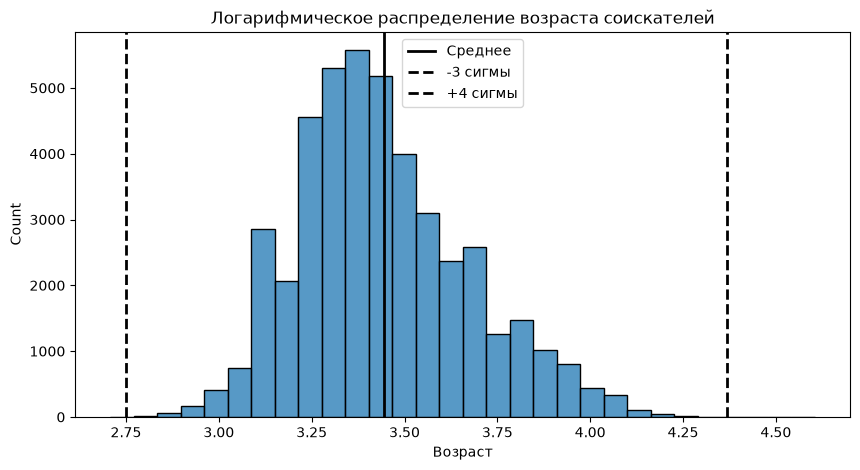

Число выбросов по возрасту: (3, 23)
Осталось записей в таблице: (44482, 23)


,Возраст,Опыт работы (месяц),ЗП (руб)
31137,15,2.0,10000.0
32950,15,3.0,2000.0
33654,100,30.0,60000.0


In [103]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Логарифмируем признак возраста (минимальный возраст > 0, поэтому + 1 не требуется)
log_age = np.log(df['Возраст'])

# 2. Строим гистограмму и добавляем линии среднего, -3 сигмы и +4 сигмы
fig, ax = plt.subplots(figsize=(10, 5))
histplot = sns.histplot(log_age, bins=30, ax=ax)
histplot.axvline(log_age.mean(), color='k', lw=2, label='Среднее')
histplot.axvline(log_age.mean() - 3 * log_age.std(), color='k', ls='--', lw=2, label='-3 сигмы')
histplot.axvline(log_age.mean() + 4 * log_age.std(), color='k', ls='--', lw=2, label='+4 сигмы')
histplot.set_title('Логарифмическое распределение возраста соискателей')
histplot.legend()
plt.show()

# 3. Функция метода z-отклонений с настройкой числа сигм влево (left=3) и вправо (right=4)
def outliers_z_score_mod(data, feature, left=3, right=3, log_scale=False):
    if log_scale:
        x = np.log(data[feature])
    else:
        x = data[feature]
    mu = x.mean()
    sigma = x.std()
    lower_bound = mu - left * sigma
    upper_bound = mu + right * sigma
    outliers = data[(x < lower_bound) | (x > upper_bound)]
    cleaned = data[(x >= lower_bound) & (x <= upper_bound)]
    return outliers, cleaned

# Применяем функцию с right=4 и log_scale=True
outliers, df = outliers_z_score_mod(df, 'Возраст', left=3, right=4, log_scale=True)

print("Число выбросов по возрасту:", outliers.shape)
print("Осталось записей в таблице:", df.shape)
display(outliers[['Возраст', 'Опыт работы (месяц)', 'ЗП (руб)']])

**Форма распределения.** У данных «тяжелый» правый хвост - то есть встречается больше необычно высоких значений, из‑за чего среднее получается больше самого частого (моды).

**Кто в выбросах.** В аномалии попали 3 резюме: двое совсем юных соискателей (по 15 лет) и один очень пожилой (100 лет) - их возраст сильно выходит за обычные рамки.